In [ ]:
import tensorflow as tf
import tensorflow.keras.backend as K
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import glob
from google.colab import drive
import os
import time
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [ ]:
def load_model(shape=(128,128,3,)):

    model = tf.keras.models.Sequential([
        tf.keras.layers.Input(shape=(128,128,3)),
        tf.keras.layers.Conv2D(4, 3, 1, padding="same", activation=tf.nn.relu),
        tf.keras.layers.Conv2D(4, 3, 1, padding="same", activation=tf.nn.relu),
        tf.keras.layers.AveragePooling2D(2, padding="same"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Conv2D(8, 3, 1, padding="same", activation=tf.nn.relu),
        tf.keras.layers.Conv2D(8, 3, 1, padding="same", activation=tf.nn.relu),
        tf.keras.layers.AveragePooling2D(2, padding="same"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Conv2D(16, 3, 1, padding="same", activation=tf.nn.relu),
        tf.keras.layers.AveragePooling2D(2, padding="same"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Conv2D(32, 3, 1, padding="same", activation=tf.nn.relu),
        tf.keras.layers.AveragePooling2D(2, padding="same"),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Conv2D(32, 3, 1, padding="same", activation=tf.nn.relu),
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dense(30, activation=tf.nn.relu),
        tf.keras.layers.Dense(3, activation=tf.nn.softmax),
    ])

    return model

In [ ]:
def get_num_masks():
    num_masks = np.array([[0.06729475, 0.17292225, 0.26379542, 0.31903485],
       [0.06998654, 0.36863271, 0.2705249 , 0.50670241],
       [0.08344549, 0.55898123, 0.2705249 , 0.68766756],
       [0.23149394, 0.10053619, 0.42664872, 0.21715818],
       [0.24091521, 0.27077748, 0.42934051, 0.4075067 ],
       [0.24091521, 0.45978552, 0.42799462, 0.59785523],
       [0.24899058, 0.65013405, 0.4320323 , 0.78820375],
       [0.4051144 , 0.01206434, 0.5948856 , 0.12466488],
       [0.40107672, 0.18096515, 0.58950202, 0.31635389],
       [0.41318977, 0.36193029, 0.59757739, 0.50402145],
       [0.4051144 , 0.5536193 , 0.5948856 , 0.68900804],
       [0.4064603 , 0.73726542, 0.60296097, 0.88203753],
       [0.56527591, 0.08713137, 0.76043069, 0.22117962],
       [0.5666218 , 0.26407507, 0.75235532, 0.40348525],
       [0.56527591, 0.44906166, 0.75504711, 0.59517426],
       [0.57065949, 0.64745308, 0.756393  , 0.77747989],
       [0.72543742, 0.17828418, 0.92462988, 0.30965147],
       [0.730821  , 0.36595174, 0.92866756, 0.49731903],
       [0.7294751 , 0.55093834, 0.92732167, 0.68766756],
       [0.04576043, 0.28418231, 0.20188425, 0.42091153],
       [0.18573351, 0.1849866 , 0.35935397, 0.32171582],
       [0.3526245 , 0.09383378, 0.52355316, 0.21983914],
       [0.04037685, 0.47184987, 0.20592194, 0.60589812],
       [0.1897712 , 0.36863271, 0.36473755, 0.51474531],
       [0.3512786 , 0.28016086, 0.52355316, 0.41823056],
       [0.52220727, 0.18096515, 0.68775236, 0.31635389],
       [0.0551817 , 0.6541555 , 0.21130552, 0.79356568],
       [0.20323015, 0.56300268, 0.36877524, 0.6997319 ],
       [0.36339166, 0.46112601, 0.52893674, 0.60053619],
       [0.51951548, 0.36595174, 0.69313594, 0.49731903],
       [0.68506057, 0.269437  , 0.84522207, 0.40080429],
       [0.20861373, 0.75603217, 0.36473755, 0.89544236],
       [0.3512786 , 0.6541555 , 0.53162853, 0.79490617],
       [0.52220727, 0.5536193 , 0.69582773, 0.69034853],
       [0.68640646, 0.46514745, 0.85195155, 0.58981233],
       [0.36339166, 0.84718499, 0.54643338, 0.97587131],
       [0.52624495, 0.75067024, 0.7039031 , 0.87533512],
       [0.69313594, 0.6461126 , 0.85733513, 0.78150134],
       [0.46837147, 0.09651475, 0.64064603, 0.21983914],
       [0.62987887, 0.18766756, 0.79946164, 0.31635389],
       [0.79004038, 0.27882038, 0.95693136, 0.41957105],
       [0.2960969 , 0.1849866 , 0.47779273, 0.31099196],
       [0.46567968, 0.27747989, 0.65006729, 0.40080429],
       [0.63795424, 0.36863271, 0.80753701, 0.49731903],
       [0.79946164, 0.46782842, 0.95020188, 0.61126005],
       [0.14266487, 0.28820375, 0.32032301, 0.41018767],
       [0.31763122, 0.38337802, 0.47913863, 0.50268097],
       [0.46567968, 0.46246649, 0.64333782, 0.5924933 ],
       [0.63122476, 0.55898123, 0.80619112, 0.68766756],
       [0.80215343, 0.65951743, 0.96096904, 0.80563003],
       [0.14266487, 0.47184987, 0.32032301, 0.59651475],
       [0.30551817, 0.56300268, 0.48452221, 0.68364611],
       [0.46837147, 0.65549598, 0.6487214 , 0.77211796],
       [0.64064603, 0.74932976, 0.80619112, 0.88739946],
       [0.15208614, 0.64477212, 0.3243607 , 0.78820375],
       [0.31090175, 0.74932976, 0.49125168, 0.87265416],
       [0.48048452, 0.84316354, 0.65006729, 0.99463807]])

    return num_masks

In [ ]:
def apply_num_masks(image, num_masks):
    masked_images=[]
    offset_x = 0
    offset_y = 0
    zoom = 0
    num_masks = (num_masks*[image.shape[1],image.shape[0],image.shape[1],image.shape[0]]).astype(int) + [offset_x, offset_y, offset_x, offset_y] + [zoom,zoom,-zoom,-zoom]
    for i in range(len(num_masks)):
        masked_images.append(image[num_masks[i,1]:num_masks[i,3],num_masks[i,0]:num_masks[i,2],:])

    return masked_images

In [ ]:
def make_images():
    path = "gdrive/My Drive/cie/t39.jpg"
    out_dir = "gdrive/My Drive/cie/data/"
    im = np.array(Image.open(path))
    # bm = np.array(np.array([0.03602258, 0.0334    , 0.96834379, 0.96573752]) * [im.shape[1],im.shape[0],im.shape[1],im.shape[0]],dtype=int)
    # im = im[bm[1]:bm[3],bm[0]:bm[2],:]
    num_images = apply_num_masks(im,get_num_masks())


    # label = [1,1,1,5,5,5,9,9,9,9,9,9,1,5,5,1,5,5,9,2,2,2,2,6,7,2,7,7,7,7,7,7,2,2,6,6,6,6,3,4,3,4,4,4,4,3,3,3,3,3,8,8,8,8,8,8,4] # t1.jpg
    # label = [5,5,5,5,5,5,5,9,9,9,9,9,1,1,1,1,1,1,9,7,2,7,6,2,2,2,7,7,7,7,7,6,7,2,6,6,6,6,4,4,4,3,3,8,3,4,8,3,3,4,8,8,8,8,3,4,3] # t2.jpg
    # label = [1, 9, 9, 1, 1, 1, 1, 5, 5, 5, 5, 1, 5, 5, 5, 5, 9, 9, 9, 7, 7, 7, 7, 2, 2, 6, 2, 2, 2, 2, 2, 6, 6, 6, 6, 7, 7, 7, 4, 4, 8, 4, 4, 3, 3, 8, 8, 8, 8, 8, 3, 3, 3, 8, 3, 4, 3] # t3.jpg
    # label = [5, 5, 5, 9, 9, 9, 9, 1, 1, 1, 1, 1, 9, 9, 9, 9, 5, 1, 5, 6, 6, 6, 7, 7, 7, 7, 2, 2, 2, 2, 2, 6, 6, 6, 6, 7, 7, 7, 8, 8, 8, 8, 8, 8, 3, 3, 3, 8, 3, 3, 4, 4, 4, 4, 4, 4, 4] # t4.jpg
    # label = [5,5,5,9,9,9,9,1,1,1,1,1,9,9,9,9,5,5,5,7,7,7,7,7,7,7,2,2,2,2,2,6,6,6,6,6,6,6,4,4,4,8,8,8,8,3,3,3,3,3,4,4,4,4,8,8,8] # t5.jpg
    # label = [1,1,1,9,5,9,9,5,5,5,5,5,1,1,1,1,1,9,9,2,2,2,6,6,6,6,7,7,7,7,7,6,7,2,7,2,2,6,3,3,3,3,4,4,3,4,8,3,3,4,8,8,8,8,8,8,8] # t6.jpg
    # label = [1,5,1,1,5,1,5,9,9,9,9,9,5,1,5,1,5,1,1,2,2,6,2,2,2,6,7,6,6,6,6,7,7,7,7,7,2,7,4,4,8,4,3,8,4,8,8,8,8,8,3,3,8,3,3,3,3] # t7.jpg
    # label = [1,1,1,1,1,1,1,5,5,5,5,5,9,9,9,9,5,1,9,7,2,2,2,2,2,2,6,6,6,6,6,7,7,7,7,7,7,6,3,3,8,8,8,8,3,4,4,4,8,4,3,3,3,3,8,8,8] # t8.jpg
    # label = [9,9,1,9,9,1,9,5,5,5,5,5,1,1,1,1,5,1,1,7,7,2,6,2,2,2,7,7,7,7,7,6,6,6,6,6,2,2,8,8,8,8,3,8,8,3,3,3,3,3,4,4,4,4,3,8,8] # t9.jpg
    # label = [9,9,9,9,1,5,1,1,9,9,1,1,5,5,5,5,9,9,9,6,2,2,7,6,2,2,2,2,6,6,7,7,2,7,7,6,6,6,8,8,8,4,8,4,3,4,4,8,3,3,4,4,4,8,3,8,8] # t10.jpg
    # label = [1,1,5,5,9,1,9,9,9,9,9,9,5,5,1,5,1,9,9,7,7,7,2,6,7,2,6,6,6,6,6,2,7,2,2,6,2,2,4,4,4,3,3,4,3,8,8,3,4,4,8,8,8,8,8,8,4] # t11.jpg
    # label = [5,5,5,9,9,9,9,1,1,9,1,1,9,9,9,9,5,1,5,7,7,2,6,6,6,2,2,2,6,2,2,7,7,7,2,6,6,6,8,8,8,8,8,4,4,3,3,8,3,4,8,3,8,4,4,4,4] # t12.jpg
    # label = [1,1,1,9,5,5,5,9,9,9,9,9,1,1,5,5,9,9,9,2,6,7,7,7,7,2,6,6,6,6,6,2,2,2,2,2,6,7,4,4,4,8,3,4,4,8,3,3,4,8,8,8,3,4,8,8,8] # t13.jpg
    # label = [9,9,5,1,5,1,1,5,5,5,5,5,1,1,1,1,9,9,9,2,2,6,2,6,2,7,7,7,7,7,7,6,6,6,6,2,2,2,8,8,8,8,3,3,3,4,3,3,3,3,8,4,4,4,4,8,4] # t14.jpg
    # label = [1,1,5,1,5,5,5,8,8,8,4,8,8,1,1,5,1,5,1,7,7,7,2,2,2,2,6,6,6,6,6,2,6,2,7,2,7,7,8,8,8,3,3,3,3,4,3,3,8,8,4,4,8,4,3,4,4] # t15.jpg
    # label = [9,9,9,9,5,9,1,1,1,1,1,1,5,5,5,1,5,5,5,2,7,7,6,6,6,6,2,2,2,2,2,2,6,6,7,7,7,7,4,3,3,8,8,4,4,4,8,4,4,3,3,3,3,3,8,8,8] # t16.jpg
    # label = [1,1,5,5,5,5,5,9,9,9,9,9,1,1,1,1,1,5,5,7,7,7,2,6,2,7,6,6,6,6,6,7,2,2,2,2,7,2,8,8,8,3,3,3,3,3,3,3,8,4,4,4,4,4,8,4,8] # t17.jpg
    # label = [1,1,1,1,5,5,5,9,9,9,9,9,1,1,9,9,1,5,1,2,2,2,6,6,6,6,7,7,7,7,7,2,2,2,2,6,7,6,4,4,3,4,4,4,4,8,8,4,8,8,3,3,3,3,8,8,8] # t18.jpg
    # label = [5,1,1,5,5,9,9,9,9,9,9,9,1,1,1,1,5,1,1,2,2,2,6,6,6,6,7,7,6,7,7,2,2,2,2,7,7,6,3,3,3,4,4,4,4,8,8,8,8,8,4,3,4,8,3,8,4] # t19.jpg
    # label = [9,5,5,9,1,1,1,9,9,9,9,9,1,5,5,1,1,1,1,7,2,2,6,6,6,6,2,2,2,2,2,7,7,7,7,6,6,7,4,4,4,8,8,8,8,3,3,3,3,3,8,8,4,8,4,4,4] # t20.jpg
    # label = [1,5,9,5,5,5,9,9,9,9,9,9,1,1,1,1,1,1,1,7,7,7,2,2,2,7,7,6,6,6,6,2,6,6,7,2,2,2,4,8,8,3,3,3,3,4,4,4,4,4,8,8,8,8,3,8,4] # t21.jpg
    # label = [9,9,9,5,5,5,5,1,5,1,5,1,1,1,1,5,1,9,9,7,2,2,6,6,7,6,6,2,2,2,7,7,7,7,7,6,6,6,8,8,8,8,8,4,4,3,3,3,3,3,4,4,4,4,8,3,3] # t22.jpg
    # label = [1,9,5,1,1,5,1,5,9,1,5,1,5,5,1,5,9,9,9,2,7,2,6,6,6,6,7,7,7,7,7,2,2,2,7,6,6,6,8,3,4,8,8,3,3,4,3,3,3,3,4,4,4,4,8,8,8] # t23.jpg
    # label = [9,9,9,1,5,1,5,1,1,1,9,9,5,5,1,5,5,9,9,2,2,2,7,7,6,7,2,7,2,2,2,6,6,6,6,7,7,7,8,4,8,4,8,3,3,3,3,3,3,3,8,8,8,8,4,4,4] # t24.jpg
    # label = [9,9,9,1,1,1,5,1,1,5,1,9,5,5,5,5,9,9,9,7,2,6,2,2,6,2,7,7,7,7,7,7,2,2,2,6,6,6,3,8,4,8,8,4,3,3,3,3,3,3,4,8,4,4,8,8,8] # t25.jpg
    # label = [5,5,9,5,9,9,9,5,5,5,1,1,1,1,1,1,9,9,9,7,7,7,2,7,6,7,6,6,6,6,6,2,2,2,2,7,7,7,4,4,4,8,3,4,3,3,8,4,4,4,8,3,3,3,8,8,8] # t26.jpg
    # label = [1,9,1,5,5,1,1,5,5,5,5,5,1,1,1,1,5,9,9,7,7,7,2,2,6,2,6,2,2,7,2,7,7,2,2,6,6,6,8,8,8,3,3,3,3,4,3,4,3,3,4,4,4,4,8,8,4] # t27.jpg
    # label = [1,1,1,5,5,5,5,5,1,5,5,5,1,1,1,1,9,9,9,7,2,7,6,2,2,7,2,7,7,7,2,6,6,6,6,2,2,2,3,3,3,8,4,8,3,4,4,4,4,4,8,8,4,8,3,3,3] # t28.jpg
    # label = [9,9,9,5,9,5,1,5,5,5,5,5,1,1,1,1,1,9,9,7,2,7,6,2,2,6,7,7,7,6,7,2,2,2,2,6,2,6,8,8,8,8,3,4,3,3,4,3,3,3,4,4,4,4,4,8,8] # t29.jpg
    # label = [9,9,1,5,1,1,5,1,1,9,1,5,5,5,5,5,9,9,9,6,2,6,2,2,2,2,7,2,2,7,7,6,6,7,7,7,2,6,4,4,4,3,3,3,3,3,4,4,4,4,3,8,8,8,8,8,8] # t30.jpg
    # label = [1,5,5,1,1,1,5,9,9,1,9,9,1,1,1,1,5,5,5,7,2,6,2,2,2,2,7,7,6,7,7,2,6,6,6,6,6,6,4,4,4,3,3,3,3,8,8,4,8,8,4,4,3,3,8,3,8] # t31.jpg
    # label = [1,1,1,1,1,1,1,1,9,9,9,9,5,5,5,5,5,1,5,7,7,6,2,2,2,7,6,6,6,6,2,2,6,7,7,6,6,2,4,4,3,3,3,3,4,8,3,3,8,4,8,8,8,8,3,4,4] # t32.jpg
    # label = [1,5,5,1,5,5,1,9,9,9,9,5,5,9,5,1,1,1,1,2,2,2,6,6,6,6,7,7,7,7,7,7,2,2,2,2,6,6,8,8,8,4,4,3,3,8,3,4,8,8,4,4,4,4,3,3,3] # t33.jpg
    # label = [5,5,5,5,1,1,5,9,9,9,9,9,1,1,1,1,5,5,1,7,7,7,2,2,2,2,6,6,6,6,6,6,2,2,2,7,7,7,4,8,8,4,4,4,3,3,3,4,4,3,8,8,8,8,4,3,3] # t34.jpg
    # label = [9,9,9,1,9,1,5,5,1,1,5,1,1,1,1,9,9,9,9,2,2,2,2,6,2,7,6,6,6,6,6,7,2,7,2,7,7,7,3,3,3,8,8,8,8,3,8,3,8,3,4,4,3,4,4,8,4] # t35.jpg
    # label = [9,9,9,1,9,1,5,5,1,1,5,1,1,1,1,9,9,9,9,2,2,2,2,6,2,7,6,6,6,6,6,7,2,7,2,7,7,7,3,3,3,8,8,8,8,3,8,3,8,3,4,4,3,4,4,8,4] # t36.jpg
    # label = [9,9,9,1,1,1,1,1,5,9,1,5,1,1,9,5,9,9,9,7,7,7,2,7,2,2,2,6,7,6,6,6,2,6,6,2,7,2,8,8,8,3,3,3,3,3,4,8,4,3,4,4,3,4,8,8,8] # t37.jpg
    # label = [9,9,9,5,5,5,5,5,1,5,1,1,1,1,1,1,9,9,9,7,7,2,2,6,2,6,6,6,6,6,6,7,6,2,6,7,2,2,8,3,4,8,8,8,8,4,3,8,4,4,3,4,4,3,3,3,3] # t38.jpg
    label = [9,9,9,1,1,1,1,5,5,5,5,5,1,1,1,5,9,9,9,7,7,7,6,6,6,6,2,2,6,2,6,6,6,2,2,7,2,6,3,3,3,3,3,3,3,4,4,4,4,4,8,8,8,8,4,8,8] # t39.jpg

    for i in range(len(num_images)):
        # plt.imshow(num_images[i])
        # plt.show()
        num=str(label[i])
        if num == "1" or num == "5" or num == "9":
          dir = "159"
        elif num == "2" or num == "6" or num == "7":
          dir = "267"
        else:
          dir = "348"
        out_path = out_dir + dir + "/val/" + str(label[i]) + "/"
        out_path = out_path + str(len(glob.glob(out_path+"*"))) +".jpg"
        Image.fromarray(num_images[i]).save(out_path)

In [ ]:
#make_images()

In [ ]:
def load_data(path, batch_size = 32, augment=False):
    if augment:
      train_gen = tf.keras.preprocessing.image.ImageDataGenerator(
                                                          rescale=1./255,
                                                          rotation_range=5,
                                                          width_shift_range=0.1,
                                                          height_shift_range=0.1,
                                                          brightness_range=[0.5,2],
                                                          channel_shift_range=100,
                                                          shear_range=0.2,
                                                          # zoom_range=0.1,
                                                          # fill_mode='nearest',
                                                          preprocessing_function=None)
    else:
      train_gen = tf.keras.preprocessing.image.ImageDataGenerator(
                                                          rescale=1./255,
                                                          )

    val_gen = tf.keras.preprocessing.image.ImageDataGenerator(
                                                          rescale=1./255,
                                                          )
    train = train_gen.flow_from_directory(path+"/train",target_size=(128, 128),
                                    batch_size=batch_size,
                                    class_mode='categorical',
                                    shuffle=True)
    val = val_gen.flow_from_directory(path+"/val",target_size=(128, 128),
                                    batch_size=1,
                                    class_mode='categorical',
                                    shuffle=True)
    return train, val

In [ ]:
def train_model(model, train_data, val_data, epochs, learning_rate = 1e-3, patience=10, suffix="159"):
    cm_es = tf.keras.callbacks.EarlyStopping("val_loss", patience=patience,restore_best_weights=True)
    model_path = f"gdrive/My Drive/cie/models/model{suffix}.h5"
    cb_mc = tf.keras.callbacks.ModelCheckpoint(
            filepath=model_path, save_weights_only=False, save_best_only=True
        )
    cb_lr = tf.keras.callbacks.ReduceLROnPlateau(
                monitor="val_loss",
                factor=0.6,
                patience=10,
            )
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate = learning_rate), loss=tf.keras.losses.categorical_crossentropy, metrics = ["accuracy"])
    history = model.fit(train_data, epochs=epochs, validation_data=val_data,verbose=1, callbacks=[cm_es, cb_mc, cb_lr])

    return history, model

In [ ]:
import numpy as np
from tensorflow.keras.models import Model
from os import path
from pathlib import Path

# =====================================
# calculate the number of floating
# point operations
# =====================================
def calc_flops(model, **kwargs):
    """
    Helper function to calculate the number of flops within a network

    Parameters
    ----------
    model
        keras model, graph model to investigate
    kwargs
        used to define the the counting variable 'flops' the starting
        point for the calculation

    Returns
    -------
    flops
        np.int64, total number of flops
    """
    # extract kwargs
    if (
        (len(kwargs) == 0)
        or ("flops" not in kwargs.keys())
    ):
        flops = .0
    else:
        flops = kwargs["flops"]
    # type checks
    if not isinstance(model, Model):
        raise TypeError("model needs to be of type 'tf.keras.models.Model'")
    if not isinstance(flops, float):
        raise TypeError("flops needs to be of type 'np.int64'")

    for layer in model.layers:
        # check if layer is graph network
        if hasattr(layer, "_is_graph_network"):
            # execute recursion
            sub_flops = calc_flops(model=layer, flops=flops)
            if not isinstance(sub_flops, type(None)):
                flops += sub_flops
        else:
            layer_type = str(type(layer))
            # TODO include more layer types
            if layer_type.find("Conv") >= 0 :
                bias = 1. if layer.use_bias else 0.
                if layer.data_format == "channels_last":
                    prev_depth = float(layer.input.shape[-1]) + bias
                elif layer.data_format == "channels_first":
                    prev_depth = float(layer.input.shape[1]) + bias
                flops += (
                    prev_depth
                    * float(np.prod(layer.output.shape[1:]))
                    * float(np.prod(layer.kernel_size))
                )
            elif layer_type.find("Dense") >= 0:
                flops += (
                    float(np.sum(layer.input.shape[1:]))
                    * float(np.sum(layer.output.shape[1:]))
                    + float(np.sum(layer.output.shape[1:]))
                )
    flops = flops
    return(flops)


# =====================================
# calculate the disk size of network
# in bytes
# =====================================
def calc_file_size(model):
    Path("tmp").mkdir(parents=True, exist_ok=True)
    model.save_weights(path.join("tmp", "neural_network"), save_format="h5")
    size = path.getsize(path.join("tmp", "neural_network"))
    Path(path.join("tmp", "neural_network")).unlink()
    Path("tmp").rmdir()

    return size


In [ ]:
model159 = load_model()
model267 = load_model()
model348 = load_model()

In [ ]:
l=model159.layers[0]

In [ ]:
print(f"{calc_flops(model159)*10e-9} GFlops")
print(f"{calc_file_size(model159)*10e-6} MB")

0.12627003 GFlops


In [ ]:
model159.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_28 (Conv2D)              │ (None, 128, 128, 4)    │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 128, 128, 4)    │           148 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_15            │ (None, 64, 64, 4)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_14          │ (None, 64, 64, 4)      │            16 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 64, 64, 8)      │           296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 64, 64, 8)      │           584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_16            │ (None, 32, 32, 8)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_15          │ (None, 32, 32, 8)      │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 32, 32, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_17            │ (None, 16, 16, 16)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 16, 16, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_18            │ (None, 8, 8, 32)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 8, 8, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 8, 8, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 30)             │           990 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │            93 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,519 (68.43 KB)

 Trainable params: 17,399 (67.96 KB)

 Non-trainable params: 120 (480.00 B)

In [ ]:
path = "gdrive/My Drive/cie/data"
train159, val159 = load_data(path+"/159", 8, augment=True)
train267, val267 = load_data(path+"/267", 8, augment=True)
train348, val348 = load_data(path+"/348", 8, augment=True)

Found 735 images belonging to 3 classes.
Found 114 images belonging to 3 classes.
Found 720 images belonging to 3 classes.
Found 114 images belonging to 3 classes.
Found 728 images belonging to 3 classes.
Found 114 images belonging to 3 classes.


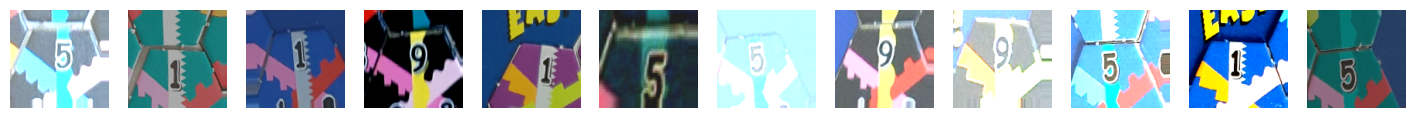

In [ ]:
fig, rows =plt.subplots(nrows=1, ncols=12, figsize=(18,18))
for row in rows:
    row.imshow(train159.__next__()[0][0].astype('float32'))
    row.axis("off")
    plt.axis("off")
plt.show()

In [ ]:
his159, model159 = train_model(model159,train159,val159,epochs=300,learning_rate=5e-4, patience=100, suffix="159_test")
his267, model267 = train_model(model267,train267,val267,epochs=300,learning_rate=5e-4, patience=100, suffix="267_test")
his348, model348 = train_model(model348,train348,val348,epochs=300,learning_rate=5e-4, patience=100, suffix="348_test")

Epoch 1/300
92/92 [==============================] - ETA: 0s - loss: 1.1134 - accuracy: 0.3483

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


92/92 [==============================] - 127s 1s/step - loss: 1.1134 - accuracy: 0.3483 - val_loss: 1.0946 - val_accuracy: 0.3860 - lr: 5.0000e-04
Epoch 2/300
92/92 [==============================] - 7s 76ms/step - loss: 1.0847 - accuracy: 0.3796 - val_loss: 1.0942 - val_accuracy: 0.3947 - lr: 5.0000e-04
Epoch 3/300
92/92 [==============================] - 7s 73ms/step - loss: 1.0435 - accuracy: 0.4871 - val_loss: 1.1127 - val_accuracy: 0.3246 - lr: 5.0000e-04
Epoch 4/300
92/92 [==============================] - 7s 74ms/step - loss: 0.9889 - accuracy: 0.5224 - val_loss: 1.1534 - val_accuracy: 0.3246 - lr: 5.0000e-04
Epoch 5/300
92/92 [==============================] - 7s 74ms/step - loss: 0.8175 - accuracy: 0.6653 - val_loss: 1.2681 - val_accuracy: 0.3860 - lr: 5.0000e-04
Epoch 6/300
92/92 [==============================] - 7s 77ms/step - loss: 0.7026 - accuracy: 0.7184 - val_loss: 0.8490 - val_accuracy: 0.5351 - lr: 5.0000e-04
Epoch 7/300
92/92 [==============================] - 7s 76

In [ ]:
model_dir = "gdrive/My Drive/cie/models"
model159.save(os.path.join(model_dir, "model159.h5"))
model267.save(os.path.join(model_dir, "model267.h5"))
model348.save(os.path.join(model_dir, "model348.h5"))

In [ ]:
model_dir = "gdrive/My Drive/cie/models"
model159 = tf.keras.models.load_model(os.path.join(model_dir, "model159_test.h5"), compile=False)
model267 = tf.keras.models.load_model(os.path.join(model_dir, "model267_test.h5"), compile=False)
model348 = tf.keras.models.load_model(os.path.join(model_dir, "model348_test.h5"), compile=False)

In [ ]:
p ="gdrive/My Drive/cie/data/159/val/1/0.jpg"
t = np.expand_dims(np.array(Image.open(p).resize((128,128))),axis=0)
print(model159.predict(t, verbose=0)[0])
p ="gdrive/My Drive/cie/data/159/val/5/0.jpg"
t = np.expand_dims(np.array(Image.open(p).resize((128,128))),axis=0)
print(model159.predict(t, verbose=0)[0])
p ="gdrive/My Drive/cie/data/159/val/9/0.jpg"
t = np.expand_dims(np.array(Image.open(p).resize((128,128))),axis=0)
print(model159.predict(t, verbose=0)[0])

p ="gdrive/My Drive/cie/data/267/val/2/0.jpg"
t = np.expand_dims(np.array(Image.open(p).resize((128,128))),axis=0)
print(model267.predict(t, verbose=0)[0])
p ="gdrive/My Drive/cie/data/267/val/6/0.jpg"
t = np.expand_dims(np.array(Image.open(p).resize((128,128))),axis=0)
print(model267.predict(t, verbose=0)[0])
p ="gdrive/My Drive/cie/data/267/val/7/0.jpg"
t = np.expand_dims(np.array(Image.open(p).resize((128,128))),axis=0)
print(model267.predict(t, verbose=0)[0])

p ="gdrive/My Drive/cie/data/348/val/3/0.jpg"
t = np.expand_dims(np.array(Image.open(p).resize((128,128))),axis=0)
print(model348.predict(t, verbose=0)[0])
p ="gdrive/My Drive/cie/data/348/val/4/0.jpg"
t = np.expand_dims(np.array(Image.open(p).resize((128,128))),axis=0)
print(model348.predict(t, verbose=0)[0])
p ="gdrive/My Drive/cie/data/348/val/8/0.jpg"
t = np.expand_dims(np.array(Image.open(p).resize((128,128))),axis=0)
print(model348.predict(t, verbose=0)[0])

[1.0000000e+00 0.0000000e+00 1.1576758e-25]
[0.000000e+00 1.000000e+00 1.567215e-20]
[0. 0. 1.]


[1. 0. 0.]
[0. 1. 0.]
[0. 0. 1.]
[0. 1. 0.]
[0. 1. 0.]
[0. 0. 1.]


In [ ]:
p ="gdrive/My Drive/cie/data/348/val/3/1.jpg"
t = np.expand_dims(np.array(Image.open(p).resize((128,128))),axis=0)
print(model348.predict(t, verbose=0)[0])

[0. 1. 0.]


In [ ]:
p ="gdrive/My Drive/cie/data/348/val/3/2.jpg"
t = np.expand_dims(np.array(Image.open(p).resize((128,128))),axis=0)
print(model348.predict(t, verbose=0)[0])

[0. 1. 0.]


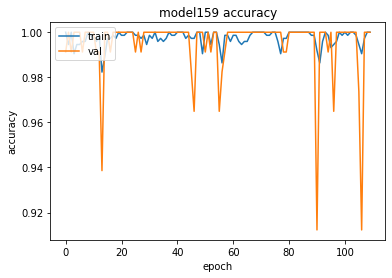

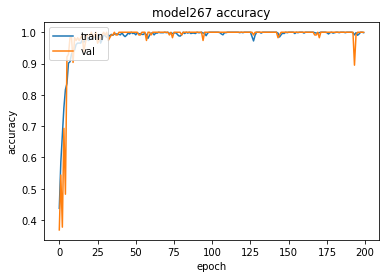

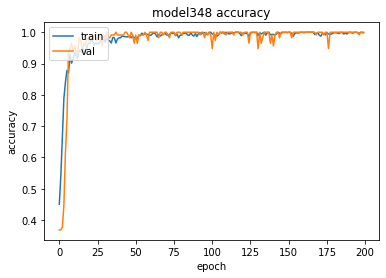

In [ ]:
plt.plot(his159.history['accuracy'])
plt.plot(his159.history['val_accuracy'])
plt.title('model159 accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

plt.plot(his267.history['accuracy'])
plt.plot(his267.history['val_accuracy'])
plt.title('model267 accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

plt.plot(his348.history['accuracy'])
plt.plot(his348.history['val_accuracy'])
plt.title('model348 accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

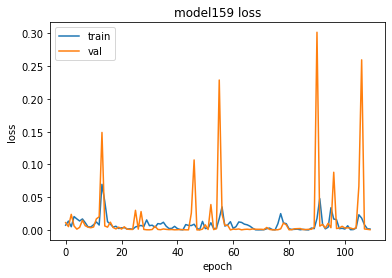

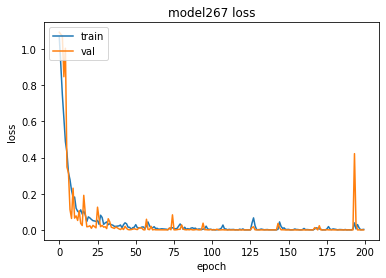

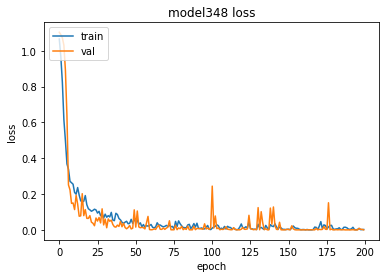

In [ ]:
plt.plot(his159.history['loss'])
plt.plot(his159.history['val_loss'])
plt.title('model159 loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

plt.plot(his267.history['loss'])
plt.plot(his267.history['val_loss'])
plt.title('model267 loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

plt.plot(his348.history['loss'])
plt.plot(his348.history['val_loss'])
plt.title('model348 loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

In [ ]:
tflite_model159 = tf.lite.TFLiteConverter.from_keras_model(model159).convert()
tflite_model267 = tf.lite.TFLiteConverter.from_keras_model(model267).convert()
tflite_model348 = tf.lite.TFLiteConverter.from_keras_model(model348).convert()

In [ ]:
save_path = "gdrive/My Drive/cie/models/"

In [ ]:
with open(save_path+"model159.tflite", "wb") as f:
  f.write(tflite_model159)
with open(save_path+"model267.tflite", "wb") as f:
  f.write(tflite_model267)
with open(save_path+"model348.tflite", "wb") as f:
  f.write(tflite_model348)

In [ ]:
with tf.io.gfile.GFile(save_path+"model159.tflite", "wb") as f:
  f.write(tflite_model159)
with tf.io.gfile.GFile(save_path+"model267.tflite", "wb") as f:
  f.write(tflite_model267)
with tf.io.gfile.GFile(save_path+"model348.tflite", "wb") as f:
  f.write(tflite_model348)

In [ ]:
class TensorFlowModel:
    def __init__(self, model_filename, num_threads=None):
        self.interpreter = tf.lite.Interpreter(
              model_filename, num_threads=num_threads
          )
        self.interpreter.allocate_tensors()

    def resize_input(self, shape):
        if list(self.get_input_shape()) != shape:
            self.interpreter.resize_tensor_input(0, shape)
            self.interpreter.allocate_tensors()

    def get_input_shape(self):
        return self.interpreter.get_input_details()[0]["shape"]

    def predict(self, x):
        # assumes one input and one output for now
        self.interpreter.set_tensor(
            self.interpreter.get_input_details()[0]["index"], x
        )
        self.interpreter.invoke()
        return self.interpreter.get_tensor(
            self.interpreter.get_output_details()[0]["index"]
        )

In [ ]:
def count_points(pred159, pred267, pred348):
  points = 0
  if pred159[0:3].min() == pred159[0:3].max():
    if pred159[0] == 0:
      points += 3
    elif pred159[0] == 1:
      points += 15
    else:
      points += 27

  if pred159[3:7].min() == pred159[3:7].max():
    if pred159[3] == 0:
      points += 4
    elif pred159[3] == 1:
      points += 20
    else:
      points += 36

  if pred159[7:12].min() == pred159[7:12].max():
    if pred159[7] == 0:
      points += 5
    elif pred159[7] == 1:
      points += 25
    else:
      points += 45

  if pred159[12:16].min() == pred159[12:16].max():
    if pred159[12] == 0:
      points += 4
    elif pred159[12] == 1:
      points += 20
    else:
      points += 36

  if pred159[16:19].min() == pred159[16:19].max():
    if pred159[16] == 0:
      points += 3
    elif pred159[16] == 1:
      points += 15
    else:
      points += 27

###

  if pred267[0:3].min() == pred267[0:3].max():
    if pred267[0] == 0:
      points += 6
    elif pred267[0] == 1:
      points += 18
    else:
      points += 21

  if pred267[3:7].min() == pred267[3:7].max():
    if pred267[3] == 0:
      points += 8
    elif pred267[3] == 1:
      points += 24
    else:
      points += 28

  if pred267[7:12].min() == pred267[7:12].max():
    if pred267[7] == 0:
      points += 10
    elif pred267[7] == 1:
      points += 30
    else:
      points += 35

  if pred267[12:16].min() == pred267[12:16].max():
    if pred267[12] == 0:
      points += 8
    elif pred267[12] == 1:
      points += 24
    else:
      points += 28

  if pred267[16:19].min() == pred267[16:19].max():
    if pred267[16] == 0:
      points += 6
    elif pred267[16] == 1:
      points += 18
    else:
      points += 21

###

  if pred348[0:3].min() == pred348[0:3].max():
    if pred348[0] == 0:
      points += 9
    elif pred348[0] == 1:
      points += 12
    else:
      points += 24
  if pred348[3:7].min()==pred348[3:7].max():
    if pred348[3] == 0:
      points += 12
    elif pred348[3] == 1:
      points += 16
    else:
      points += 32
  if pred348[7:12].max() == pred348[7:12].min():
    if pred348[7] == 0:
      points += 15
    elif pred348[7] == 1:
      points += 20
    else:
      points += 40
  if pred348[12:16].min() == pred348[12:16].max():
    if pred348[12] == 0:
      points += 12
    elif pred348[12] == 1:
      points += 16
    else:
      points += 32
  if pred348[16:19].min() == pred348[16:19].max():
    if pred348[16] == 0:
      points += 9
    elif pred348[16] == 1:
      points += 12
    else:
      points += 24

  return points

In [ ]:
def predict_on_img(path, model159, model267, model348):
  im = np.array(Image.open(path))
  ims = apply_num_masks(im,get_num_masks())
  ims159 = ims[:19]
  ims267 = ims[19:38]
  ims348 = ims[38:]

  for i in range(19):
    ims159[i] = np.array(Image.fromarray(ims159[i]).resize((128,128)))
    ims267[i] = np.array(Image.fromarray(ims267[i]).resize((128,128)))
    ims348[i] = np.array(Image.fromarray(ims348[i]).resize((128,128)))

  pred159 = np.argmax(np.array([model159.predict(x[None,...]) for x in ((np.array(ims159)*(1/255)).astype(np.float32))]),axis=-1)
  pred267 = np.argmax(np.array([model267.predict(x[None,...]) for x in ((np.array(ims267)*(1/255)).astype(np.float32))]),axis=-1)
  pred348 = np.argmax(np.array([model348.predict(x[None,...]) for x in ((np.array(ims348)*(1/255)).astype(np.float32))]),axis=-1)

  return pred159, pred267, pred348

In [ ]:
def count_it_easy(path, model159, model267, model348):
  pred159, pred267, pred348 = predict_on_img(path, model159, model267, model348)
  points = count_points(pred159, pred267, pred348)
  return points

In [ ]:
model_dir = "gdrive/My Drive/cie/models"
tflite_model159 = TensorFlowModel(os.path.join(model_dir, "model159.tflite"))
tflite_model267 = TensorFlowModel(os.path.join(model_dir, "model267.tflite"))
tflite_model348 = TensorFlowModel(os.path.join(model_dir, "model348.tflite"))

In [ ]:
model_dir = "gdrive/My Drive/cie/models"
model159 = tf.keras.models.load_model(os.path.join(model_dir, "model159.h5"), compile=False)
model267 = tf.keras.models.load_model(os.path.join(model_dir, "model267.h5"), compile=False)
model348 = tf.keras.models.load_model(os.path.join(model_dir, "model348.h5"), compile=False)

In [ ]:
path = "gdrive/My Drive/cie/t5.jpg"
points = count_it_easy(path, tflite_model159, tflite_model267, tflite_model348)
print(points)

NameError: name 'tflite_model159' is not defined

In [ ]:
path = "gdrive/My Drive/cie/t5.jpg"
points = count_it_easy(path, model159, model267, model348)
print(points)

245


In [ ]:
gt = [170,181,167,245,307]

In [ ]:
path = "gdrive/My Drive/cie/t4.jpg"
t = time.time()
for _ in range(100):
  _ = count_it_easy(path, tflite_model159, tflite_model267, tflite_model348)
ct = (time.time()-t)/100
print(f"{round(ct, 3)}s total count time")

0.117s total count time
